# 08 Performance
Part 5 of the brief for all seven tasks: input-size parameters, theoretical complexity, measured times and whether they agree.

**Size parameters.** $V$ nodes, $E$ pipes, $|S|$ sources (2 in every instance), $n$ locations to visit (task 6), $n$ candidate connections (task 7).

**Method.** Every time is the median of 21 samples (`water.timing.median_time`), each sample looping the call long enough to last at least 2 ms; branch and bound uses the median of 3 runs because single runs take up to seconds. Four instances span only $20\le V\le 71$, too narrow to show growth, so growth is measured on subsets of increasing size: induced sub-networks of PES grown in breadth-first order from both sources (every node keeps a path to a source), office-nearest subsets for task 6 (as in `06_sampling_route`), and random subsets of the PES candidates for task 7. For each curve the expected cost model $g(n)$ is scaled by a single least-squares constant $c$ (in log space) and drawn dashed; the fitted log-log slope is compared with the model's.

Absolute times are from one machine and include Python interpreter overhead, which dominates at these tiny sizes; the relevant evidence is the growth rate and the ratio between alternatives.

In [1]:
import os, sys
if 'google.colab' in sys.modules and not os.path.isdir('../water'):
    os.system('git clone -q https://github.com/santihdzs/water-distribution')
    os.chdir('water-distribution/notebooks')
sys.path.insert(0, os.path.abspath('..'))

import math
import random
import platform
from collections import deque
import matplotlib.pyplot as plt
import numpy as np
import water
from water import flow, graph, paths, plot, spatial, tasks, timing, tsp
from water.io import Network

plot.setup()
nets = water.load_all()
print(platform.python_version(), platform.machine(), platform.system())

3.13.2 arm64 Darwin


In [2]:
def subnetwork(net, n):
    """first n nodes in multi-source bfs order from the sources, with every pipe among them."""
    adj = graph.adjacency_list(net)
    seen, queue = list(net.sources), deque(net.sources)
    while queue and len(seen) < n:
        u = queue.popleft()
        for v, _ in adj[u]:
            if v not in seen and len(seen) < n:
                seen.append(v); queue.append(v)
    keep = set(seen)
    return Network(f'{net.name}[{n}]', {u: net.coords[u] for u in keep}, list(net.sources),
                   [p for p in net.pipes if p[0] in keep and p[1] in keep], None, [], (n, None))

def fit(n, t, model):
    """constant c minimising the log error of t ~ c * model(n), and the measured log-log slope."""
    n, t = np.asarray(n, float), np.asarray(t, float)
    c = math.exp(np.mean(np.log(t) - np.log(model(n))))
    slope = np.polyfit(np.log(n), np.log(t), 1)[0]
    return c, slope

def flow_pair(net):
    """source 1 to the farthest node it reaches, as in task 5 but on the whole (sub)network."""
    d, *_ = paths.dijkstra(graph.adjacency_list(net), net.sources[0])
    return net.sources[0], max(d, key=lambda u: (d[u], -u))

PES = nets['PES']
sizes = [10, 18, 26, 34, 42, 50, 58, 66, 71]
subs = [subnetwork(PES, n) for n in sizes]
assert all(len(graph.components(graph.adjacency_list(s))) <= 2 for s in subs)

## Polynomial algorithms on growing PES sub-networks (tasks 1 to 5)

In [3]:
grow = {k: [] for k in ['V', 'E', 'bfs_list', 'bfs_matrix', 'dij_multi', 'dij_rep', 'fw', 'ek', 'dinic', 'len_loop', 'len_np']}
for net in subs:
    adj = graph.adjacency_list(net)
    M, ids, index = graph.adjacency_matrix(net)
    s, t = flow_pair(net)
    xy = np.array([[*net.coords[u], *net.coords[v]] for u, v, _ in net.pipes])
    grow['V'].append(len(net.coords)); grow['E'].append(len(net.pipes))
    grow['bfs_list'].append(timing.median_time(lambda: graph.components(adj)))
    grow['bfs_matrix'].append(timing.median_time(lambda: graph.components_matrix(M)))
    grow['dij_multi'].append(timing.median_time(lambda: paths.multi_source_dijkstra(adj, net.sources)))
    grow['dij_rep'].append(timing.median_time(lambda: paths.repeated_dijkstra(adj, net.sources)))
    grow['fw'].append(timing.median_time(lambda: paths.floyd_warshall(M)))
    grow['ek'].append(timing.median_time(lambda: flow.edmonds_karp(net.pipes, s, t)))
    grow['dinic'].append(timing.median_time(lambda: flow.dinic(net.pipes, s, t)))
    grow['len_loop'].append(timing.median_time(lambda: [net.length(u, v) for u, v, _ in net.pipes]))
    grow['len_np'].append(timing.median_time(lambda: np.hypot(xy[:, 0] - xy[:, 2], xy[:, 1] - xy[:, 3])))

V, E = np.array(grow['V']), np.array(grow['E'])
models = {'bfs_list': ('components, list', lambda n: n + E[np.searchsorted(V, n)], 1),
          'bfs_matrix': ('components, matrix', lambda n: n ** 2, 2),
          'dij_multi': ('multi-source Dijkstra', lambda n: (n + E[np.searchsorted(V, n)]) * np.log(n), 1),
          'dij_rep': ('repeated Dijkstra', lambda n: (n + E[np.searchsorted(V, n)]) * np.log(n), 1),
          'fw': ('Floyd-Warshall', lambda n: n ** 3, 3),
          'len_loop': ('lengths, loop', lambda n: E[np.searchsorted(V, n)], 1)}
for key, (label, model, expected) in models.items():
    c, slope = fit(V, grow[key], model)
    print(f'{label:24s} V {V[0]}..{V[-1]}: {grow[key][0]*1e6:8.1f} -> {grow[key][-1]*1e6:9.1f} us '
          f'(x{grow[key][-1]/grow[key][0]:5.1f}), log-log slope {slope:.2f}, model exponent ~{expected}')
print(f'matrix / list component search at V = {V[-1]}: {grow["bfs_matrix"][-1] / grow["bfs_list"][-1]:.1f}x')
print(f'repeated / multi-source Dijkstra time ratio: {np.median(np.array(grow["dij_rep"]) / np.array(grow["dij_multi"])):.2f} (|S| = 2)')
print(f'Edmonds-Karp / Dinic time ratio: {np.median(np.array(grow["ek"]) / np.array(grow["dinic"])):.2f}')

components, list         V 10..71:      1.7 ->      10.3 us (x  6.2), log-log slope 0.94, model exponent ~1
components, matrix       V 10..71:      5.7 ->     173.5 us (x 30.5), log-log slope 1.76, model exponent ~2
multi-source Dijkstra    V 10..71:      3.4 ->      29.7 us (x  8.7), log-log slope 1.10, model exponent ~1
repeated Dijkstra        V 10..71:      5.4 ->      58.5 us (x 10.8), log-log slope 1.16, model exponent ~1
Floyd-Warshall           V 10..71:     21.5 ->     703.2 us (x 32.7), log-log slope 1.82, model exponent ~3
lengths, loop            V 10..71:      0.6 ->       6.0 us (x  9.8), log-log slope 1.17, model exponent ~1
matrix / list component search at V = 71: 16.9x
repeated / multi-source Dijkstra time ratio: 1.41 (|S| = 2)
Edmonds-Karp / Dinic time ratio: 0.40


## Task 6: exact versus heuristic routes on office-nearest subsets

In [4]:
bnb = []
for name, net in nets.items():
    D, nxt, ids, index = tasks.metric_closure(net)
    o = index[net.office]
    order = list(np.argsort(D[o], kind='stable'))
    for k in range(4, 17, 2):
        Ds = D[np.ix_(order[:k], order[:k])]
        t_h = timing.median_time(lambda: tsp.two_opt(Ds, tsp.nearest_neighbor(Ds, 0)))
        t2, _ = tsp.two_opt(Ds, tsp.nearest_neighbor(Ds, 0))
        t_b = timing.median_time(lambda: tsp.branch_and_bound(Ds, 0, t2), repeats=3, min_sample=0)
        bnb.append((name, k, t_b, t_h))
for name in nets:
    k = np.array([b[1] for b in bnb if b[0] == name]); tb = np.array([b[2] for b in bnb if b[0] == name])
    rate = math.exp(np.polyfit(k[k >= 8], np.log(tb[k >= 8]), 1)[0])
    th = [b[3] for b in bnb if b[0] == name]
    print(f'{name}: B&B {tb[0]*1e3:.2f} ms (k=4) -> {tb[-1]*1e3:,.1f} ms (k=16), growth x{rate:.2f} per added node '
          f'| NN + 2-opt {th[0]*1e6:.0f} -> {th[-1]*1e6:.0f} us')

NYT: B&B 0.08 ms (k=4) -> 81.0 ms (k=16), growth x1.42 per added node | NN + 2-opt 2 -> 65 us
HAN: B&B 0.04 ms (k=4) -> 324.7 ms (k=16), growth x2.24 per added node | NN + 2-opt 2 -> 65 us
FOS: B&B 0.05 ms (k=4) -> 135.7 ms (k=16), growth x1.73 per added node | NN + 2-opt 2 -> 97 us
PES: B&B 0.05 ms (k=4) -> 1,894.5 ms (k=16), growth x2.13 per added node | NN + 2-opt 2 -> 67 us


## Task 7: nearest-node search and graph update

In [5]:
cand = [(u, xy) for u, xy in sorted(PES.coords.items()) if u not in PES.sources]
rng = random.Random(7)
x0, x1, y0, y1 = PES.bbox()
queries = [(rng.uniform(x0, x1), rng.uniform(y0, y1)) for _ in range(200)]
nn_sizes = [5, 10, 20, 30, 40, 50, 60, 69]
nn = {'brute': [], 'tree': [], 'build': [], 'evals': []}
for n in nn_sizes:
    pts = dict(rng.sample(cand, n))
    tree = spatial.KDTree(pts)
    nn['brute'].append(timing.median_time(lambda: [spatial.brute_nearest(pts, q) for q in queries]) / len(queries))
    nn['tree'].append(timing.median_time(lambda: [tree.nearest(q) for q in queries]) / len(queries))
    nn['build'].append(timing.median_time(lambda: spatial.KDTree(pts)))
    nn['evals'].append(np.mean([tree.nearest(q)[2] for q in queries]))
for i, n in enumerate(nn_sizes):
    print(f'n={n:2d}: brute {nn["brute"][i]*1e6:6.2f} us/query, tree {nn["tree"][i]*1e6:6.2f} us/query '
          f'({nn["evals"][i]:.1f} evaluations), build {nn["build"][i]*1e6:7.1f} us, '
          f'break-even after {nn["build"][i] / max(nn["brute"][i] - nn["tree"][i], 1e-12):.0f} queries')

upd = {'list': [], 'matrix': []}
for net in subs:
    adj = graph.adjacency_list(net)
    M, ids, index = graph.adjacency_matrix(net)
    target, nid = ids[-1], max(ids) + 1
    def add_list():
        a = dict(adj); a[nid] = [(target, 1.0)]; a[target] = adj[target] + [(nid, 1.0)]
    def add_matrix():
        out = np.zeros((len(M) + 1, len(M) + 1)); out[:-1, :-1] = M
        out[-1, index[target]] = out[index[target], -1] = 1.0
    upd['list'].append(timing.median_time(add_list))
    upd['matrix'].append(timing.median_time(add_matrix))
print('graph update, list:', ', '.join(f'{t*1e6:.2f}' for t in upd['list']), 'us')
print('graph update, matrix:', ', '.join(f'{t*1e6:.2f}' for t in upd['matrix']), 'us')

n= 5: brute   0.50 us/query, tree   1.13 us/query (3.5 evaluations), build     1.8 us, break-even after 1807455 queries
n=10: brute   0.86 us/query, tree   1.66 us/query (6.1 evaluations), build     3.8 us, break-even after 3807455 queries
n=20: brute   1.52 us/query, tree   1.80 us/query (7.1 evaluations), build     8.4 us, break-even after 8409668 queries
n=30: brute   2.14 us/query, tree   2.06 us/query (8.5 evaluations), build    13.6 us, break-even after 173 queries
n=40: brute   2.85 us/query, tree   2.27 us/query (9.3 evaluations), build    19.3 us, break-even after 34 queries
n=50: brute   3.39 us/query, tree   2.41 us/query (10.1 evaluations), build    25.4 us, break-even after 26 queries
n=60: brute   4.04 us/query, tree   2.45 us/query (10.4 evaluations), build    31.5 us, break-even after 20 queries
n=69: brute   4.63 us/query, tree   2.58 us/query (11.0 evaluations), build    37.2 us, break-even after 18 queries


graph update, list: 0.18, 0.16, 0.18, 0.19, 0.25, 0.21, 0.23, 0.24, 0.24 us
graph update, matrix: 0.40, 0.47, 0.58, 0.67, 0.81, 0.97, 1.11, 1.78, 1.89 us


In `add_list` the dict copy stands in for keeping the original intact between repetitions; it is $O(V)$ and makes the list timing an upper bound on the true $O(1)$ in-place update.

## Summary table on the four instances

In [6]:
cols = {}
for name, net in nets.items():
    adj = graph.adjacency_list(net)
    M, ids, index = graph.adjacency_matrix(net)
    sec = tasks.sectorize(net); far = tasks.farthest(net, sec)
    D, nxt, _, _ = tasks.metric_closure(net)
    o = index[net.office]
    pts = {u: xy for u, xy in net.coords.items() if u not in net.sources}
    tree = spatial.KDTree(pts)
    q = net.new[0][:2]
    us = lambda f, **kw: timing.median_time(f, **kw) * 1e6
    cols[name] = (len(ids), len(net.pipes), [
                 us(lambda: graph.components(adj)), us(lambda: graph.components_matrix(M)),
                 us(lambda: paths.multi_source_dijkstra(adj, net.sources)), us(lambda: paths.repeated_dijkstra(adj, net.sources)),
                 us(lambda: tasks.sector_flows(net, sec, far, flow.edmonds_karp)), us(lambda: tasks.sector_flows(net, sec, far, flow.dinic)),
                 us(lambda: paths.floyd_warshall(M)), us(lambda: tsp.two_opt(D, tsp.nearest_neighbor(D, o))),
                 us(lambda: spatial.brute_nearest(pts, q)), us(lambda: tree.nearest(q))])
    print(name, ' | '.join(f'{x:.1f}' for x in cols[name][2]))
labels = ['T1 components, adjacency list', 'T1 components, adjacency matrix', 'T3 multi-source Dijkstra',
          'T3 repeated Dijkstra', 'T5 Edmonds-Karp, both sectors', 'T5 Dinic, both sectors', 'T2/T6 Floyd-Warshall',
          'T6 NN + 2-opt, full route', 'T7 nearest node, brute force', 'T7 nearest node, 2-d tree']
plot.table('performance', [[lab] + [cols[n][2][i] for n in nets] for i, lab in enumerate(labels)],
           ['Algorithm'] + [f'{n} ({cols[n][0]}, {cols[n][1]})' for n in nets], ['{}'] + ['{:,.1f}'] * len(nets))

NYT 2.8 | 16.7 | 7.2 | 15.1 | 12.2 | 19.8 | 49.9 | 103.6 | 1.4 | 1.1


HAN 4.3 | 37.2 | 11.1 | 24.0 | 16.9 | 30.5 | 105.4 | 268.0 | 2.2 | 1.4


FOS 5.9 | 50.2 | 17.3 | 33.5 | 46.6 | 101.0 | 138.3 | 536.0 | 2.4 | 1.3


PES 10.4 | 173.8 | 29.7 | 58.9 | 60.7 | 112.9 | 692.8 | 2602.0 | 4.7 | 2.1


## Figure

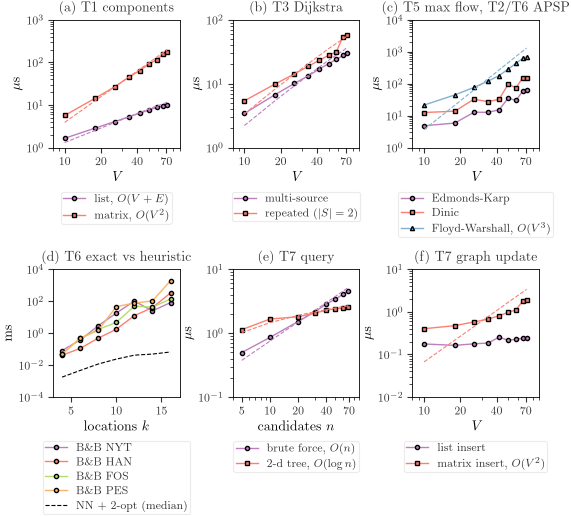

In [7]:
fig, axs = plt.subplots(2, 3, figsize=(6.27, 4.9), gridspec_kw={'hspace': 0.95, 'wspace': 0.42})
leg = dict(loc='upper center', bbox_to_anchor=(0.5, -0.3), ncol=1)

def curve(ax, x, y, key_label, color, marker, model=None):
    ax.plot(x, np.array(y) * 1e6, marker=marker, ms=3, lw=1.0, color=color, label=key_label)
    if model is not None:
        c, _ = fit(x, y, model)
        xs = np.asarray(x, float)
        ax.plot(xs, c * model(xs) * 1e6, ls='--', lw=0.8, color=color)

ax = axs[0, 0]
curve(ax, V, grow['bfs_list'], 'list, $O(V+E)$', plot.PALETTE[0], 'o', models['bfs_list'][1])
curve(ax, V, grow['bfs_matrix'], 'matrix, $O(V^2)$', plot.PALETTE[1], 's', models['bfs_matrix'][1])
ax.set(title='(a) T1 components', xlabel='$V$')
ax = axs[0, 1]
curve(ax, V, grow['dij_multi'], 'multi-source', plot.PALETTE[0], 'o', models['dij_multi'][1])
curve(ax, V, grow['dij_rep'], 'repeated ($|S|=2$)', plot.PALETTE[1], 's', models['dij_rep'][1])
ax.set(title='(b) T3 Dijkstra', xlabel='$V$')
ax = axs[0, 2]
curve(ax, V, grow['ek'], 'Edmonds-Karp', plot.PALETTE[0], 'o')
curve(ax, V, grow['dinic'], 'Dinic', plot.PALETTE[1], 's')
curve(ax, V, grow['fw'], 'Floyd-Warshall, $O(V^3)$', plot.PALETTE[8], '^', models['fw'][1])
ax.set(title='(c) T5 max flow, T2/T6 APSP', xlabel='$V$')
ax = axs[1, 0]
for j, name in enumerate(nets):
    k = [b[1] for b in bnb if b[0] == name]
    ax.plot(k, [b[2] * 1e3 for b in bnb if b[0] == name], 'o-', ms=3, lw=1.0, color=plot.PALETTE[j], label=f'B\\&B {name}')
ax.plot(k, [np.median([b[3] for b in bnb if b[1] == kk]) * 1e3 for kk in k], 'k--', lw=0.8, label='NN + 2-opt (median)')
ax.set(title='(d) T6 exact vs heuristic', xlabel='locations $k$', ylabel='ms')
ax = axs[1, 1]
curve(ax, nn_sizes, nn['brute'], 'brute force, $O(n)$', plot.PALETTE[0], 'o', lambda n: n)
curve(ax, nn_sizes, nn['tree'], '2-d tree, $O(\\log n)$', plot.PALETTE[1], 's', lambda n: np.log2(n))
ax.set(title='(e) T7 query', xlabel='candidates $n$')
ax = axs[1, 2]
curve(ax, V, upd['list'], 'list insert', plot.PALETTE[0], 'o')
curve(ax, V, upd['matrix'], 'matrix insert, $O(V^2)$', plot.PALETTE[1], 's', lambda n: n ** 2)
ax.set(title='(f) T7 graph update', xlabel='$V$')
for ax in axs.flat:
    ax.set_yscale('log')
    if ax is not axs[1, 0]:
        ax.set_xscale('log')
        ax.set_ylabel(r'$\mu$s')
        ax.set_xlim(4 if ax is axs[1, 1] else 8, 90)
        ticks = [5, 10, 20, 40, 70] if ax is axs[1, 1] else [10, 20, 40, 70]
        ax.set_xticks(ticks, [str(x) for x in ticks])
        ax.xaxis.set_minor_formatter(plt.NullFormatter())
    ax.legend(**leg)
axs[1, 0].set_xlim(3, 17)
plot.save(fig, 'performance')
plt.show()

## Agreement with theory
- **T1.** Component search on the matrix grows with log-log slope about 1.8 against $V$ (model 2: it scans $V$ cells per vertex), on the list with slope about 0.9 (model 1); at $V=71$ the matrix is about 17 times slower, as $O(V^2)$ against $O(V+E)$ predicts for sparse graphs.
- **T2.** Computing all pipe lengths grows linearly (slope about 1.2). Floyd-Warshall grows with slope about 1.8, below the model's 3, because each of its $V$ steps is one vectorised $O(V^2)$ NumPy update whose fixed per-call cost dominates while $V^2\le 5{,}041$; the number of elementary operations is exactly $V^3$, and the measured curve steepens towards the dashed $V^3$ reference as $V$ grows.
- **T3.** Both Dijkstra variants follow $(V+E)\log V$ (slopes about 1.1 and 1.2). Repeated Dijkstra performs exactly twice the relaxations of the multi-source version (`03_sectorization`); its time ratio is 1.4 on the median subset and 2.0 on the full PES instance, where fixed overheads matter least.
- **T5.** Edmonds-Karp and Dinic grow roughly linearly, far below their $O(VE^2)$ and $O(V^2E)$ worst cases, because these source-sink pairs need only 1 to 4 augmenting paths (`05_max_flow`), each one $O(E)$ BFS. Edmonds-Karp is about 2.5 times faster: Dinic's level graph, arc pointers and recursive DFS cost more than they save when a phase contains one or two augmenting paths. Dinic's advantage needs many augmentations per phase, which these sectors do not have.
- **T6.** Branch and bound grows exponentially with the number of locations, by a factor of about 1.4 (NYT) to 2.2 (HAN) per added node, from about 0.05 ms at $k=4$ to between about 80 ms and 2 s at $k=16$, while NN + 2-opt stays below 0.1 ms. The growth is irregular because pruning depends on how tight the MST bound is for each subset. This is the only task whose cost explodes, and it is why the full HAN, FOS and PES routes are only approximate.
- **T7.** Brute-force query time grows linearly with $n$ (about 0.5 to 4.7 microseconds); the 2-d tree grows far more slowly (about 1.1 to 2.6 microseconds, 3.5 to 11 distance evaluations), the expected logarithmic trend, and it is faster from about 30 candidates. Its build pays for itself only after a few tens of queries, so for the two or three insertions per instance brute force is enough. The list insert stays near-constant; the matrix insert grows about 5 times from $V=10$ to 71, less than the $V^2$ model because copying at most 5,041 cells costs little next to NumPy's allocation overhead; its quadratic growth would dominate on larger networks.